In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    PrecisionRecallDisplay
)
import joblib

In [2]:
import warnings 
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

In [3]:
df=pd.read_csv("AIML Dataset.csv")

In [9]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [11]:
df.info(0)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [13]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [15]:
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [17]:
df["isFlaggedFraud"].value_counts()

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

In [19]:
df.isnull().sum().sum()

0

In [20]:
df.shape

(6362620, 11)

In [21]:
round((df["isFraud"].value_counts()[1]/df.shape[0])*100,2)

0.13

In [29]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Data types and missing values
df.info()

print("\nMissing values:")
print(df.isnull().sum())

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Fraud distribution
print(df["isFraud"].value_counts())

print("\nFraud percentage:")
print((df["isFraud"].value_counts(normalize=True) * 100).round(3))

Dataset shape: (6362620, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB

Missing values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64
Duplicate rows: 0
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud percentage:
isFraud
0    99.871
1     0.129
Name: proportion, dtype: float64


## Exploratory Data Analysis(EDA)

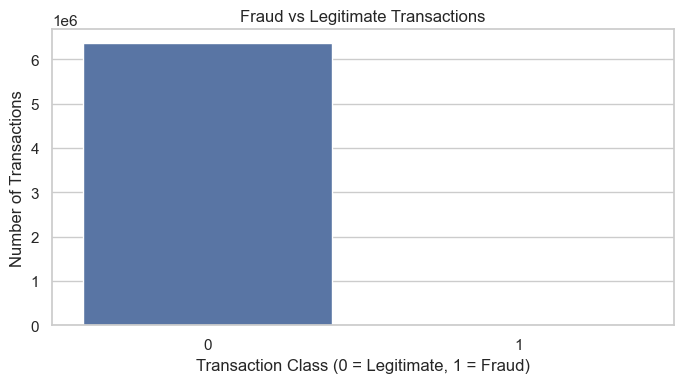

In [30]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="isFraud")

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

## Analyze fraud by transaction type

          Fraud_Count  Total_Transactions  Fraud_Rate
type                                                 
TRANSFER         4097              532909    0.768799
CASH_OUT         4116             2237500    0.183955
CASH_IN             0             1399284    0.000000
DEBIT               0               41432    0.000000
PAYMENT             0             2151495    0.000000


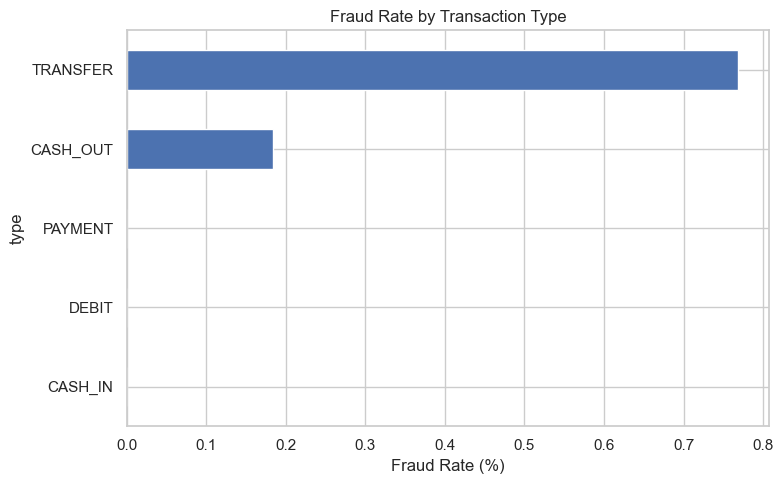

In [33]:

fraud_by_type = (
    df.groupby("type")["isFraud"]
      .agg(["sum", "count", "mean"])
      .rename(columns={
          "sum": "Fraud_Count",
          "count": "Total_Transactions",
          "mean": "Fraud_Rate"
      })
)

fraud_by_type["Fraud_Rate"] *= 100

print(fraud_by_type.sort_values("Fraud_Rate", ascending=False))

fraud_by_type["Fraud_Rate"].sort_values().plot(
    kind="barh", figsize=(8, 5)
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Fraud Rate (%)")
plt.tight_layout()
plt.show()

## Compare transaction amounts

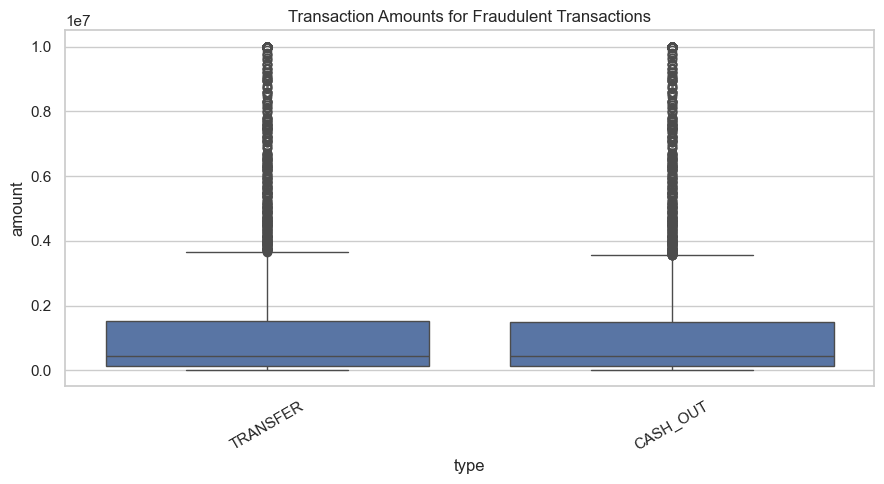

In [35]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df[df["isFraud"] == 1],
    x="type",
    y="amount"
)

plt.title("Transaction Amounts for Fraudulent Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Compare balances before and after transactions

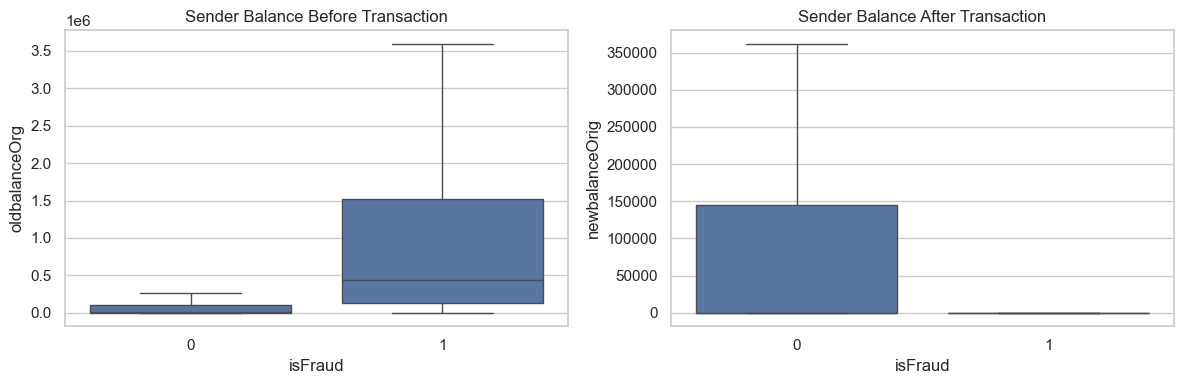

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(
    data=df,
    x="isFraud",
    y="oldbalanceOrg",
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title("Sender Balance Before Transaction")

sns.boxplot(
    data=df,
    x="isFraud",
    y="newbalanceOrig",
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("Sender Balance After Transaction")

plt.tight_layout()
plt.show()

## Prepare the data for machine learning

In [44]:
# Reproducible sample that preserves the original class proportion
df_model = df.sample(
    n=min(500_000, len(df)),
    random_state=42
)

print("Model dataset shape:", df_model.shape)
print(df_model["isFraud"].value_counts())
print(df_model["isFraud"].value_counts(normalize=True))

Model dataset shape: (500000, 11)
isFraud
0    499353
1       647
Name: count, dtype: int64
isFraud
0    0.998706
1    0.001294
Name: proportion, dtype: float64


## Create the features and target

In [47]:
# Remove identifiers and the pre-existing fraud flag
X = df_model.drop(
    columns=["isFraud", "isFlaggedFraud", "nameOrig", "nameDest"]
)

y = df_model["isFraud"]

# Convert the transaction type to a categorical feature
X["type"] = X["type"].astype(str)

print("Features:", X.columns.tolist())
print("Target shape:", y.shape)

Features: ['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
Target shape: (500000,)


## Split into training and testing sets

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining fraud proportion:")
print(y_train.mean())

print("\nTesting fraud proportion:")
print(y_test.mean())

Training rows: 400000
Testing rows: 100000

Training fraud proportion:
0.001295

Testing fraud proportion:
0.00129


## first fraud detection model

In [53]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = ["type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        )
    )
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


## Generate predictions

In [56]:
y_pred = logistic_model.predict(X_test)

# Fraud probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

Predictions completed!


## Evaluate the model correctly

In [59]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))
print("Average Precision:", average_precision_score(y_test, y_prob))

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.95      0.97     99871
       Fraud       0.02      0.95      0.05       129

    accuracy                           0.95    100000
   macro avg       0.51      0.95      0.51    100000
weighted avg       1.00      0.95      0.97    100000

Precision: 0.02414407282802296
Recall: 0.9457364341085271
F1-score: 0.047086067155538404
Average Precision: 0.5500909624316123


## Confusion matrix

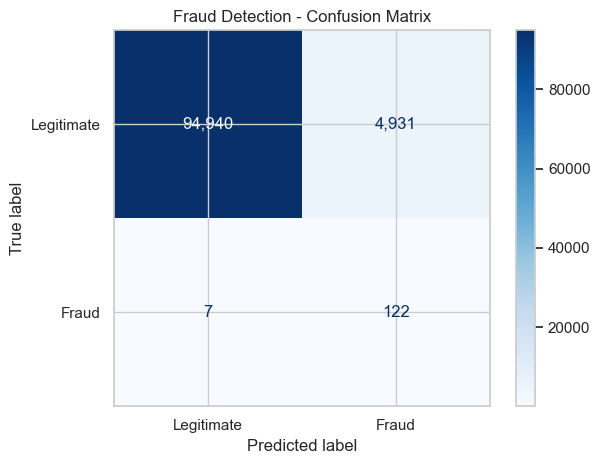

In [62]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
)

disp.plot(cmap="Blues", values_format=",")
plt.title("Fraud Detection - Confusion Matrix")
plt.tight_layout()
plt.show()

## Precision-recall curve

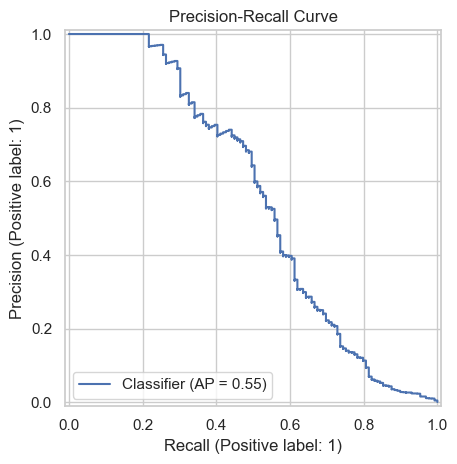

In [65]:
PrecisionRecallDisplay.from_predictions(y_test, y_prob)

plt.title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

## Compare with a Random Forest model

In [68]:
rf_train = X_train.sample(
    n=min(150_000, len(X_train)),
    random_state=42
)

rf_y_train = y_train.loc[rf_train.index]

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_model.fit(rf_train, rf_y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest results")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("Precision:", precision_score(y_test, rf_pred, zero_division=0))
print("Recall:", recall_score(y_test, rf_pred, zero_division=0))
print("F1-score:", f1_score(y_test, rf_pred, zero_division=0))
print("Average Precision:", average_precision_score(y_test, rf_prob))

Random Forest results
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     99871
       Fraud       0.97      0.76      0.85       129

    accuracy                           1.00    100000
   macro avg       0.98      0.88      0.93    100000
weighted avg       1.00      1.00      1.00    100000

Precision: 0.9702970297029703
Recall: 0.7596899224806202
F1-score: 0.8521739130434782
Average Precision: 0.8678130281827242


## Compare the results

In [71]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],
    "F1_Score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ],
    "Average_Precision": [
        average_precision_score(y_test, y_prob),
        average_precision_score(y_test, rf_prob)
    ]
})

print(results.round(4))

                 Model  Precision  Recall  F1_Score  Average_Precision
0  Logistic Regression     0.0241  0.9457    0.0471             0.5501
1        Random Forest     0.9703  0.7597    0.8522             0.8678


In [ ]:
## 